# B1 | Figure 2

Saved SHINE results. Training seed 123; K=11; clustering seed 0.

Five-fit summaries use seeds 0, 1, 2, 123 and 1234. See [setup and data requirements](README.md).

Inputs: pre-registered SMA data released with [NicheTrans](https://github.com/YSTLab/NicheTrans), restricted to the frozen common paired cohort. Registration precedes SHINE training.


In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import shine
from shine import SHINE, normalize_counts
from shine.study import Section

CASE = "B1"
# Extract the figure-data archive into data/, or set SHINE_DATA_ROOT.
search_roots = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("SHINE_DATA_ROOT"):
    ROOT = Path(os.environ["SHINE_DATA_ROOT"]).expanduser().resolve()
else:
    ROOT = next((candidate for parent in search_roots
                 for candidate in (parent / "data", parent)
                 if (candidate / "revision_experiments").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the figure-data archive into data/, or set SHINE_DATA_ROOT. See data/README.md.")
manifest_candidates = [p / name for p in search_roots
                       for name in ("sections.json", "notebooks/sections.json")]
manifest_candidates.append(ROOT / "SHINE-github/notebooks/sections.json")
MANIFEST = next((p for p in manifest_candidates if p.is_file()), None)
if MANIFEST is None:
    raise FileNotFoundError("Cannot find notebooks/sections.json.")
import sys
sys.path.insert(0, str(MANIFEST.parent))
from figure_plotting import spatial_results, regional_results, molecular_maps, attention_plot, save_panel

OUT = ROOT / "outputs/notebook_results_20261124" / CASE
OUT.mkdir(parents=True, exist_ok=True)
section = Section(ROOT, MANIFEST, CASE)
print("shine-omics", shine.__version__, "|", CASE, "|", len(section.spots), "paired spots")

shine-omics 0.1.0.dev1 | B1 | 2455 paired spots


## 1. Settings

Fixed figure settings and paired cohort. Source files are verified by SHA-256.

In [2]:
settings = {"Figure": section.config["figure"], "K": section.config["K"],
            "epochs": 120, "training_seed": 123,
            "clustering_seed": section.config["display_clustering_seed"],
            "final_ReLU": True, **section.config["model_options"]}
display(pd.Series(settings, name="Final setting").to_frame())
display(section.spots.groupby(["region", "lesion"], dropna=False).size().rename("paired_spots").reset_index())

,Final setting
Figure,2
K,11
epochs,120
training_seed,123
clustering_seed,0
final_ReLU,True
loss,original
l2,True
spatial_floor,0.0
latent_dim,128


,region,lesion,paired_spots
0,ACB,intact,109
1,ACB,lesioned,120
2,CP,intact,250
3,CP,lesioned,301
4,CTX,intact,514
5,CTX,lesioned,510
6,LSX,intact,89
7,LSX,lesioned,77
8,MSC,intact,22
9,MSC,lesioned,33


## 2. Inputs

These paired matrices are already preprocessed. Do not repeat normalization or registration.

In [3]:
print(section.config["preprocessing"])
input_audit = pd.DataFrame([
    {"modality": name, "spots": x.shape[0], "features": x.shape[1],
     "finite": bool(np.isfinite(x).all()), "constant_rows": int((x.std(1) == 0).sum()),
     "minimum": float(x.min()), "maximum": float(x.max())}
    for name, x in [("RNA", section.rna), ("MSI", section.msi)]])
display(input_audit)
assert section.spots.spot.is_unique
assert np.allclose(section.xy, section.spots[["x", "y"]])
# For raw counts: normalize_counts(full_counts, feature_indices=frozen_columns)
# Do not renormalize section.rna or section.msi.

Frozen NicheTrans paired cohort. RNA: all-gene total 10000/log1p, frozen paper B1 2000 genes. MSI: TIC 10000/log1p, frozen paired assignment. Do not normalize inputs.npz again.


,modality,spots,features,finite,constant_rows,minimum,maximum
0,RNA,2455,2000,True,0,0.0,7.098983
1,MSI,2455,1538,True,0,0.0,7.186159


## 3. Graphs

H5 + H20; spatial kNN6; feature correlation-kNN20; local self+6 attention. Graphs use no annotation labels.

In [4]:
data, graphs = section.prepare()
display(pd.Series(graphs["audit"], name="Graph audit").to_frame())
print("Validated tensor shape:", data.shape)
print("Input + graph fingerprint:", data.fingerprint())

<reference-environment>/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,Graph audit
n_spots,2455
spatial_k,6
feature_k,20
hyperedge_sizes,"[5, 20]"
n_hyperedges,4910
pca_components,30
pca_seed,0
constant_feature_rows,"[0, 0]"
allow_constant_feature_rows,True
labels_used,False


Validated tensor shape: (2455, 2000, 1538)
Input + graph fingerprint: fbec9d807bde279bdf87be4dd9997ec947d9eedd37723e5743975603fb161b98


## 4. Model

Replay the saved figure model. Set `RUN_NEW_TRAINING=True` for a separate 120-epoch fit.

In [5]:
model, labels, replay_audit = section.replay(data)
display(pd.Series(replay_audit).to_frame("Replay check"))
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    new_model = SHINE(**section.config["model_options"])
    def progress(record):
        if record["epoch"] % 20 == 0:
            print("Epoch", record["epoch"], "loss", round(record["total"], 5))
    new_model.fit(data, epochs=120, seed=123, lr=1e-4, weight_decay=1e-3, progress=progress)
    new_labels = new_model.cluster(section.config["K"], seed=section.config["display_clustering_seed"])
    new_model.save(OUT / "new_training_seed123.pt")
    display(section.score(new_labels))
else:
    print("Displaying the saved figure model.")

,Replay check
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2455
origin,saved figure checkpoint; new package inference


Displaying the saved figure model.


## 5. ARI and NMI

Average five clustering seeds within each fit, then report mean and sample SD over five training seeds. Regional scores retain whole-section cluster IDs.

In [6]:
display_metrics = section.score(labels)
raw_metrics, per_fit, summary = section.five_fit_metrics()
print("Displayed fit: seed 123")
display(display_metrics.round(4))
print("Five fits: mean and sample SD")
display(summary.round(4))
display(per_fit.round(4))
for name, table in [("display_metrics", display_metrics), ("all_partitions", raw_metrics),
                    ("per_training_fit", per_fit), ("five_fit_summary", summary)]:
    table.to_csv(OUT / (name + ".csv"), index=False)

Displayed fit: seed 123


,endpoint,n_scored,ARI,NMI
0,Whole section,2346,0.3821,0.5962
1,CP,551,0.6832,0.6779


Five fits: mean and sample SD


,endpoint,ARI_mean,ARI_std,NMI_mean,NMI_std,n_fits
0,CP,0.7649,0.0583,0.7125,0.0533,5
1,Whole section,0.4020,0.0228,0.6010,0.0135,5


,endpoint,training_seed,ARI,NMI
0,CP,0,0.7986,0.7284
1,CP,1,0.6989,0.6446
2,CP,2,0.7948,0.7361
3,CP,123,0.7059,0.6739
4,CP,1234,0.8262,0.7793
5,Whole section,0,0.4369,0.6095
6,Whole section,1,0.3920,0.5825
7,Whole section,2,0.4124,0.6173
8,Whole section,123,0.3881,0.5941
9,Whole section,1234,0.3805,0.6018


## 6. Spatial partition and UMAP

Manuscript colors and spatial rendering; seed 123. Filled display cells remove scatter gaps without changing measured spots or cluster IDs. Grey denotes unlabelled or unpaired tissue. UMAP is used only for visualization.


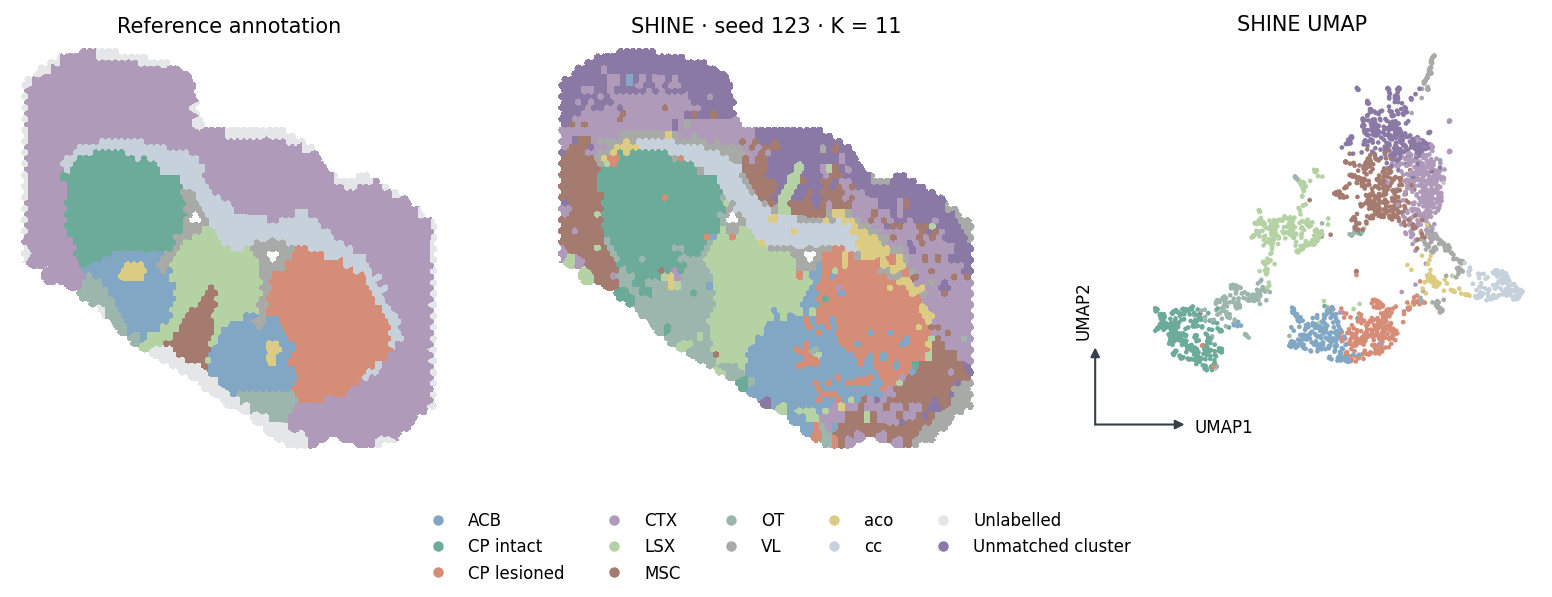

In [7]:
import umap
saved_embedding = np.load(section.path("embedding_123"))
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=123, n_jobs=1).fit_transform(saved_embedding)
fig = spatial_results(section, labels, umap_xy)
save_panel(fig, OUT / "seed123_spatial_UMAP")
plt.show()
spatial_source = section.spots.copy()
spatial_source["SHINE_cluster"] = labels
spatial_source[["UMAP1", "UMAP2"]] = umap_xy
spatial_source.to_csv(OUT / "seed123_spatial_source.csv", index=False)

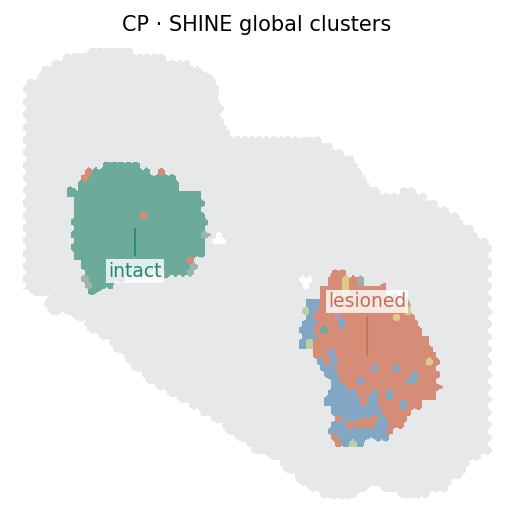

In [8]:
fig = regional_results(section, labels)
save_panel(fig, OUT / "seed123_regions")
plt.show()

## 7. Attention

Spatial-branch weights within RNA and MSI. These are mixing weights, not causal importance.

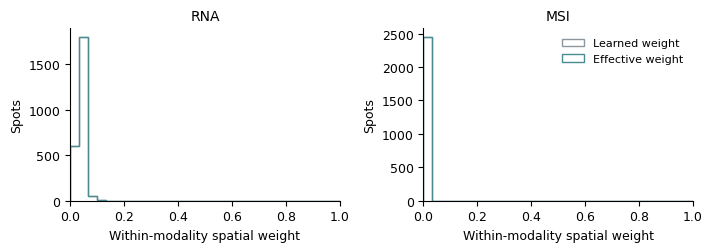

,RNA_spatial_raw,RNA_spatial_effective,MSI_spatial_raw,MSI_spatial_effective
count,2455.000,2455.000,2455.000,2455.000
mean,0.040,0.040,0.016,0.016
std,0.010,0.010,0.002,0.002
min,0.024,0.024,0.009,0.009
25%,0.033,0.033,0.014,0.014
50%,0.038,0.038,0.016,0.016
75%,0.045,0.045,0.017,0.017
max,0.146,0.146,0.026,0.026


In [9]:
fig = attention_plot(model)
save_panel(fig, OUT / "attention_weights")
plt.show()
attention_source = pd.DataFrame({"spot": section.spots.spot,
    "RNA_spatial_raw": model.attention_["rna_raw"][:, 0],
    "RNA_spatial_effective": model.attention_["rna"][:, 0],
    "MSI_spatial_raw": model.attention_["msi_raw"][:, 0],
    "MSI_spatial_effective": model.attention_["msi"][:, 0]})
attention_source.to_csv(OUT / "attention_source.csv", index=False)
display(attention_source.drop(columns="spot").describe().round(3))

## 8. Measured genes and MSI peaks

Shared Figure 2 markers. Anatomical-side effects and cluster comparisons are reported separately.

RNA: ['Penk', 'Pcp4', 'Tac1', 'Sfxn1', 'Cst3', 'Cartpt']
MSI m/z: ['674.28833', '390.16864', '674.28592', '435.20692', '675.29202', '674.28050']


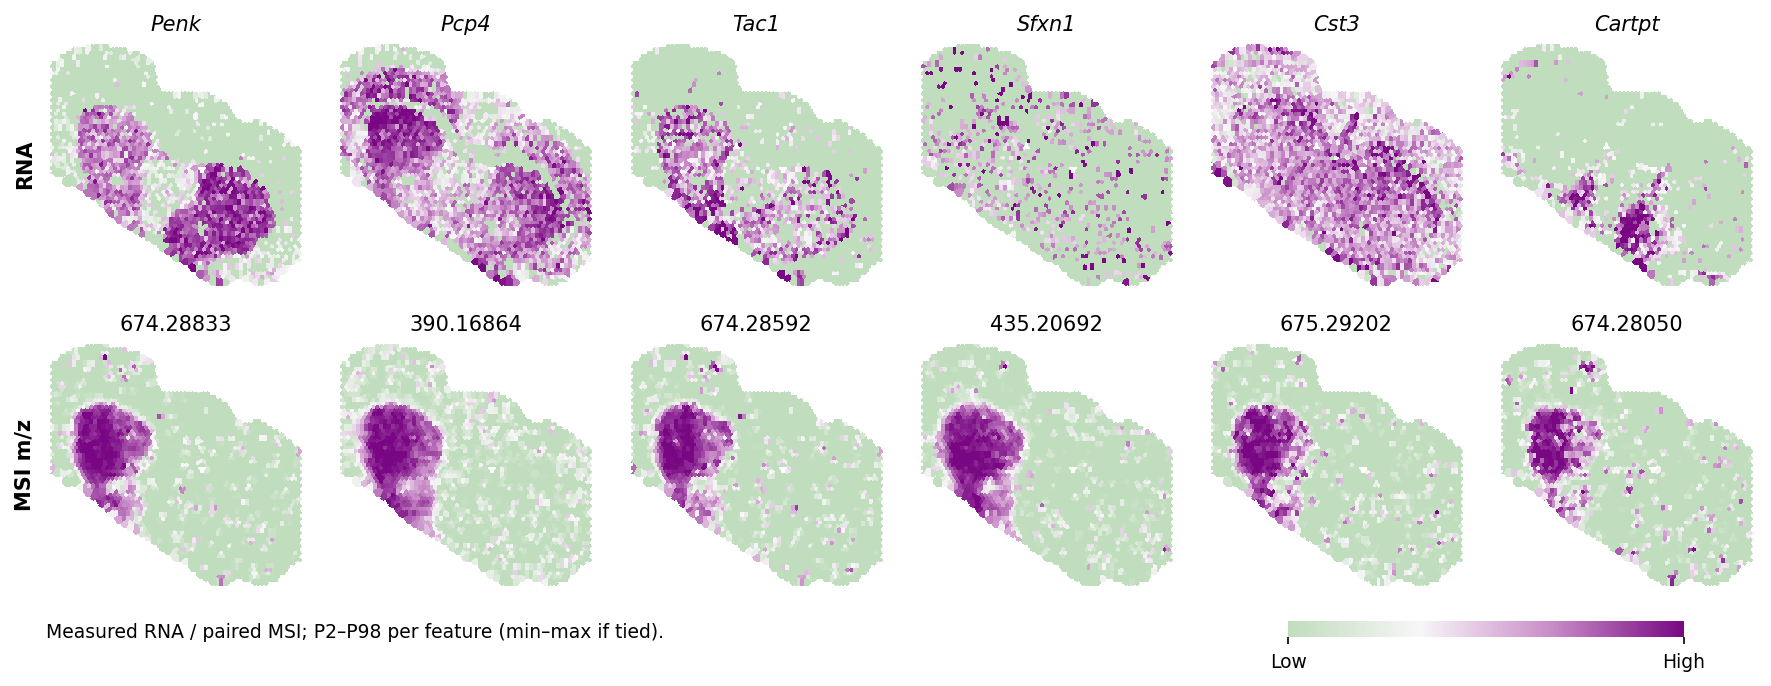

,contrast,feature,n_reference,n_target,mean_reference,mean_target,difference_SD
0,CP: lesioned minus intact,Penk,250,301,2.684,3.534,0.998
1,CP: lesioned minus intact,Pcp4,250,301,3.174,2.714,-0.688
2,CP: lesioned minus intact,Tac1,250,301,1.490,1.068,-0.484
3,CP: lesioned minus intact,Sfxn1,250,301,0.469,0.201,-0.514
4,CP: lesioned minus intact,Cst3,250,301,3.785,3.913,0.323
5,CP: lesioned minus intact,Cartpt,250,301,0.032,0.368,0.625
6,CP: lesioned minus intact,674.28833,250,301,2.090,0.110,-1.923
7,CP: lesioned minus intact,390.16864,250,301,2.835,0.178,-1.946
8,CP: lesioned minus intact,674.28592,250,301,1.787,0.113,-1.881
9,CP: lesioned minus intact,435.20692,250,301,2.270,0.127,-1.935


In [10]:
molecules = section.molecular_values()
print("RNA:", section.config["display_genes"])
print("MSI m/z:", section.config["display_peaks"])
fig = molecular_maps(section, molecules)
save_panel(fig, OUT / "measured_molecules")
plt.show()
measured_source = pd.concat([section.spots[["spot", "x", "y", "region", "lesion"]], molecules], axis=1)
measured_source.to_csv(OUT / "measured_molecule_source.csv", index=False)
effects = section.molecular_comparison(molecules, labels)
display(effects.round(3))
effects.to_csv(OUT / "measured_molecule_effects.csv", index=False)

## 9. CP clusters and pathways

Frozen Figure 2 results. Metascape used the top 100 genes per cluster and a mouse-genome background.

In [11]:
section.verify("molecular_selection")
cluster_molecules = pd.read_csv(section.path("molecular_selection"))
cluster_molecules = cluster_molecules[cluster_molecules.section.eq(CASE)]
display(cluster_molecules[["side", "cluster", "feature", "modality", "cluster_mean", "centered_mean_SD"]].round(3))
section.verify("enrichment")
enrichment = pd.read_csv(section.path("enrichment"))
display(enrichment[enrichment.section.eq(CASE)])

,side,cluster,feature,modality,cluster_mean,centered_mean_SD
24,intact,6,Penk,RNA,2.674,-0.557
25,lesioned,0,Penk,RNA,3.561,0.485
26,intact,6,Pcp4,RNA,3.170,0.369
27,lesioned,0,Pcp4,RNA,2.860,-0.094
28,intact,6,Tac1,RNA,1.471,0.243
29,lesioned,0,Tac1,RNA,1.083,-0.203
30,intact,6,Sfxn1,RNA,0.476,0.294
31,lesioned,0,Sfxn1,RNA,0.209,-0.219
32,intact,6,Cst3,RNA,3.788,-0.168
33,lesioned,0,Cst3,RNA,3.929,0.186


,GO,term,class,section,side,cluster,GeneList,Category,Log(q-value),#GeneInGOAndHitList,#GeneInHitList,Hits,reported,q_approx,gene_ratio
2,mmu04728,Dopaminergic synapse,SS,B1,intact,6,B1_I_C6,KEGG Pathway,-1.20,4.0,96.0,Drd1|Prkcb|Prkcg|Ppp1ca,True,6.309573e-02,0.041667
3,mmu04728,Dopaminergic synapse,SS,B1,lesioned,0,B1_L_C0,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
8,GO:0014059,regulation of dopamine secretion,SS,B1,intact,6,B1_I_C6,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
9,GO:0014059,regulation of dopamine secretion,SS,B1,lesioned,0,B1_L_C0,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
14,GO:0050433,regulation of catecholamine secretion,SS,B1,intact,6,B1_I_C6,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
15,GO:0050433,regulation of catecholamine secretion,SS,B1,lesioned,0,B1_L_C0,GO Biological Processes,-3.30,5.0,99.0,Adora2a|Chga|Cnr1|Drd2|Cartpt,True,5.011872e-04,0.050505
20,WP2910,Mecp2 and associated Rett syndrome,ND,B1,intact,6,B1_I_C6,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
21,WP2910,Mecp2 and associated Rett syndrome,ND,B1,lesioned,0,B1_L_C0,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
26,GO:0098916,anterograde trans-synaptic signaling,SS,B1,intact,6,B1_I_C6,GO Biological Processes,-1.10,6.0,96.0,Cplx2|Drd1|Egr3|Grin1|Prkcg|Slc17a7,True,7.943282e-02,0.062500
27,GO:0098916,anterograde trans-synaptic signaling,SS,B1,lesioned,0,B1_L_C0,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN


## 10. Validation and exports

Saved-model replay and fresh training are reported separately. Fresh fits do not replace the figure model.

In [7]:
validation_dir = ROOT / "outputs/shine_omics_notebooks_validation_20261124" / CASE
for filename in ["replay_validation.json", "fresh_training_validation.json"]:
    path = validation_dir / filename
    if path.exists():
        display(pd.Series(json.loads(path.read_text()), name=filename).to_frame())
    else:
        print(filename, "Not available; training validation is incomplete.")
provenance = {"case": CASE, "package_version": shine.__version__, "settings": settings,
              "replay": replay_audit, "sources": section.config["sources"],
              "statistical_unit": "training seed; sample SD over five fits",
              "spatial_train_seed": 123, "new_training_replaces_figure": False}
(OUT / "notebook_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Output directory:", OUT)

,replay_validation.json
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2455
origin,saved figure checkpoint; new package inference
graph_audit,"{'n_spots': 2455, 'spatial_k': 6, 'feature_k':..."
data_fingerprint,fbec9d807bde279bdf87be4dd9997ec947d9eedd37723e...
seconds,33.097969


,fresh_training_validation.json
case,B1
epochs,120
training_seed,123
seconds,1068.74447
finite_embedding,True
fresh_vs_historical_max_abs_error,0.0
partition_ARI_vs_historical,1.0
main_figure_overwritten,False


Output directory: $SHINE_DATA_ROOT/outputs/notebook_results_20261124/B1
